# Couchbase SF=200: before and after doubling memory

This comparison illustrates JSONBench's diagnostic use: distinguish memory-related query-engine failures from timeouts that persist with more memory. Both completed matrices ran on the same 16-vCPU / 32 GiB host, with three repetitions and client counts 2–64.

| Configuration | Total service cap | Data/bucket quota | Index quota |
|---|---:|---:|---:|
| Original (`paper-v1`) | 12 GiB | 4 GiB | 2 GiB |
| Doubled (`paper-memory24-v1`) | 24 GiB | 8 GiB | 4 GiB |

This changes the complete memory configuration, not only the total cap. Versions, source revision, dataset and workload protocol are held fixed. The two matrices ran sequentially, not in randomized treatment order. Neither comparison includes the later diagnostic indexes or query rewrites.

**Bars:** each repetition's outcome counts are normalized to percentages, then the three percentages are averaged equally. Success + error + timeout sums to 100%. Queries must start within measurement; their drain outcomes are included. These are attempt shares, not fractions of wall-clock downtime. Rapid failures can inflate the number of attempts.

**OOM annotations:** kernel-recorded `cbq-engine` kills within these SF=200 run-attempt intervals, including setup/warmup/drain. They are not precisely aligned to measurement windows. The journal is filtered to each matrix's start/end times to exclude earlier experiments.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "jsonbench/matrix.py").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from utilities import load_outcomes, validate_paired_runs

OUT = ROOT / "analysis/ec2-memory-comparison-figures"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 200, "savefig.dpi": 200, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "savefig.bbox": "tight"})
before = load_outcomes(ROOT / "analysis/ec2-large-results/paper-v1", backend="couchbase", scale_factor=200,
                       kernel_log="kernel-20261110T2215.log")
after = load_outcomes(ROOT / "analysis/ec2-large-memory24-results/paper-memory24-v1", backend="couchbase", scale_factor=200,
                      kernel_log="collected-logs/kernel-journal.log")
validate_paired_runs(before, after)
comparison = pd.concat([before.assign(memory_gib=12), after.assign(memory_gib=24)], ignore_index=True)
comparison.drop(columns=["queries"]).to_csv(OUT / "paired_run_outcomes.csv", index=False)
print("Validated 18 matched configurations/repetitions per memory setting against raw events.")

Validated 18 matched configurations/repetitions per memory setting against raw events.


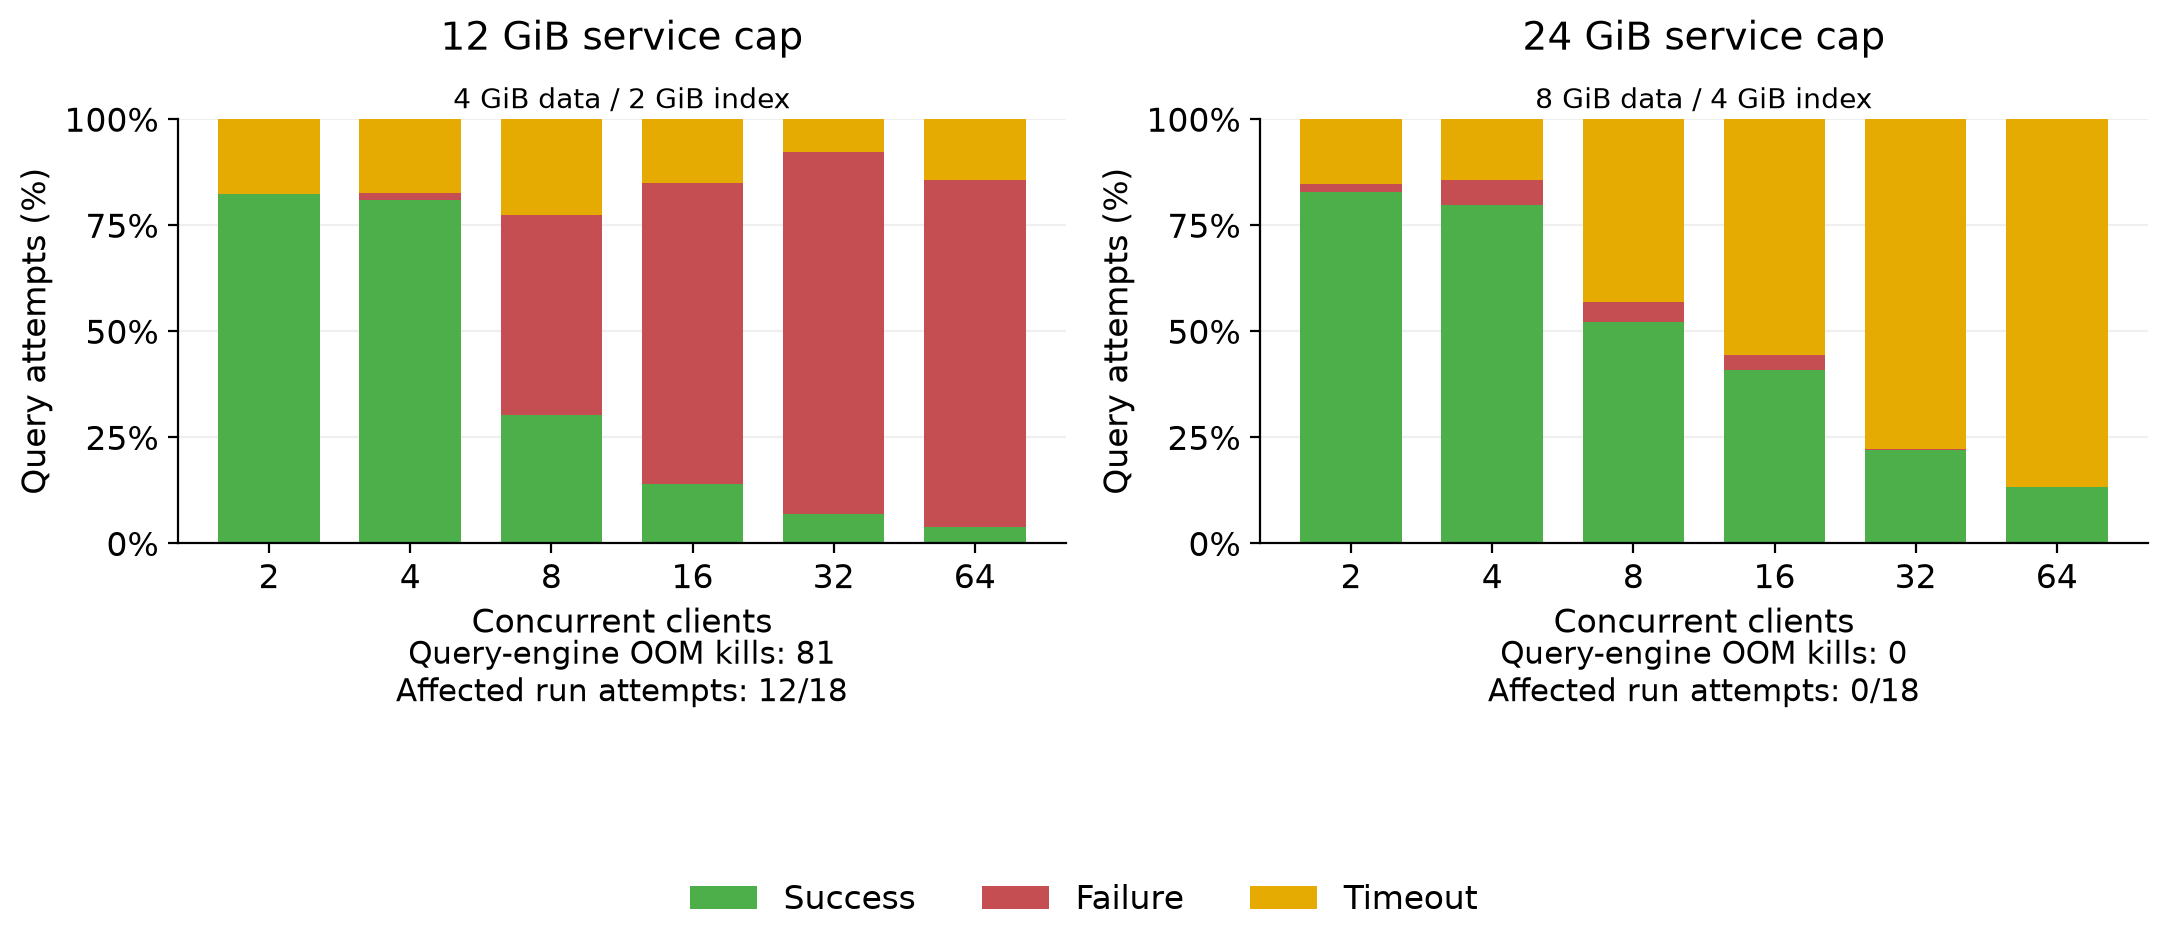

In [2]:
labels = {"success": "Success", "error": "Failure", "timeout": "Timeout"}
colors = {"success": "#4daf4a", "error": "#c44e52", "timeout": "#e6ab02"}
percentages = comparison[["memory_gib", "clients", "repetition"]].copy()
for outcome in labels:
    percentages[outcome] = 100 * comparison[outcome] / comparison.admitted
np.testing.assert_allclose(percentages[list(labels)].sum(axis=1), 100)
means = percentages.groupby(["memory_gib", "clients"])[list(labels)].mean()
np.testing.assert_allclose(means.sum(axis=1), 100)
percentages.to_csv(OUT / "run_outcome_percentages.csv", index=False)
means.to_csv(OUT / "mean_outcome_percentages.csv")
clients = [2, 4, 8, 16, 32, 64]
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, memory, quotas in zip(axes, [12, 24], ["4 GiB data / 2 GiB index", "8 GiB data / 4 GiB index"]):
    values = means.loc[memory].reindex(clients)
    bottom = np.zeros(len(clients))
    for outcome, label in labels.items():
        ax.bar(np.arange(len(clients)), values[outcome], bottom=bottom, width=.72,
               color=colors[outcome], label=label)
        bottom += values[outcome].to_numpy()
    selected = comparison[comparison.memory_gib == memory]
    kills = int(selected.oom_kills.sum())
    affected = int(selected.oom_kills.gt(0).sum())
    ax.set_title(f"{memory} GiB service cap", fontsize=14, pad=25)
    ax.text(.5, 1.01, quotas, ha="center", va="bottom", transform=ax.transAxes, fontsize=10)
    ax.set_xticks(np.arange(len(clients)), clients)
    ax.set_xlabel("Concurrent clients")
    ax.set_ylabel("Query attempts (%)")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.tick_params(labelleft=True)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.2)
    ax.text(.5, -.22, f"Query-engine OOM kills: {kills}\nAffected run attempts: {affected}/18",
            ha="center", va="top", transform=ax.transAxes, fontsize=11)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, .12, 1, .96))
fig.savefig(OUT / "couchbase_sf200_memory_outcomes.png", dpi=200)
fig.savefig(OUT / "couchbase_sf200_memory_outcomes.pdf")
plt.show()

## Supporting counts

Counts below are pooled across the 18 runs per setting; chart percentages instead give each repetition equal weight within a client count. A lower error count does not imply every formerly failing query succeeded: requests may instead time out, and total attempt counts change in a closed-loop workload. These aggregate observations do not link individual requests across runs.

In [3]:
totals = comparison.groupby("memory_gib")[["admitted", "success", "error", "timeout", "oom_kills"]].sum()
totals.index.name = "Service cap (GiB)"
totals.to_csv(OUT / "outcome_totals.csv")
display(totals)
display(means.round(2))

,admitted,success,error,timeout,oom_kills
Service cap (GiB),,,,,
12,6790,356,5981,453,81
24,1321,374,17,930,0


success  error  timeout
memory_gib clients                         
12         2          82.43   0.00    17.57
           4          80.93   1.67    17.40
           8          30.28  47.04    22.68
           16         14.02  70.94    15.03
           32          6.96  85.29     7.75
           64          3.91  81.85    14.24
24         2          82.75   1.96    15.29
           4          79.78   5.96    14.26
           8          52.28   4.60    43.12
           16         40.93   3.55    55.52
           32         22.00   0.30    77.69
           64         13.32   0.00    86.68